# From the Model to Samples: Evaluation and Control on One Toy MDP
### Exact solution, simple iterations, Monte Carlo, TD(0), SARSA and Q-learning

**ESE 561, Theory of Artificial Intelligence.**

We evaluate **one fixed policy** $\pi$ four ways and check that all four give the same $V^\pi$:

| § | Method | Needs the model $P$? | Idea |
|---|---|---|---|
| 2 | inverse matrix | yes | solve $V=r^\pi+\gamma P^\pi V$ exactly |
| 3 | simple iterations | yes | $V_{k+1}=T^\pi V_k$, a $\gamma$-contraction |
| 5 | Monte Carlo | no | average of sampled returns $G_t$ |
| 6 | TD(0) | no | sampled version of $V_{k+1}=T^\pi V_k$ |

Sections 2–3 **plan** with a known model; sections 4–8 treat the same MDP as an **unknown environment** that we can only sample.

Sections 9–13 then **improve** the policy without a model: SARSA and Expected SARSA (sampled $Q\leftarrow T^{\pi_\varepsilon}Q$) and Q-learning (sampled value iteration $Q\leftarrow BQ$). The whole notebook runs in about a minute.

In [1]:
import warnings
warnings.filterwarnings("ignore", message="pkg_resources is deprecated")
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, Circle
from matplotlib import animation
from IPython.display import HTML
import gymnasium as gym
np.set_printoptions(precision=4, suppress=True)
plt.rcParams['figure.figsize'] = (7, 4.2)

## 1. The toy MDP and the policy

* States $A$, $B$ and the terminal $G$ ($V(G)=0$).
* In $A$: **stay** (reward $+1$, remain in $A$) or **go** (reach $B$ w.p. 0.8, slip back to $A$ w.p. 0.2).
* In $B$: **cash** (reach $G$ with reward $+20$ w.p. 0.7, fall back to $A$ w.p. 0.3) or **back** (return to $A$).
* Discount $\gamma=0.9$.

The policy we evaluate is $\pi=(\text{go},\ \text{cash})$. The model is stored as `P[(s, a)]` = list of `(next state, probability, reward)`.

In [ ]:
STATES = ['A', 'B', 'G']
TERMINAL = {'G'}
ACTIONS = {'A': ['stay', 'go'], 'B': ['cash', 'back'], 'G': []}
P = {('A', 'stay'): [('A', 1.0, 1.0)],
     ('A', 'go'):   [('B', 0.8, 0.0), ('A', 0.2, 0.0)],
     ('B', 'cash'): [('G', 0.7, 20.0), ('A', 0.3, 0.0)],
     ('B', 'back'): [('A', 1.0, 0.0)]}
gamma = 0.9
pi = {'A': 'go', 'B': 'cash'}          # the policy we evaluate

In [ ]:
COL = {'stay': '#1f5fa8', 'go': '#c0392b', 'cash': '#1e8449', 'back': '#7d3c98'}

def _arrow(ax, p, q, color, lw=1.6, rad=0.0, alpha=1.0, z=1, shrinkA=17, shrinkB=17):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle='-|>', mutation_scale=13, color=color, lw=lw,
                                 connectionstyle=f'arc3,rad={rad}', shrinkA=shrinkA, shrinkB=shrinkB,
                                 alpha=alpha, zorder=z))

def _node(ax, xy, text, fc='white', r=0.28, fs=11, ec='k', lw=1.3):
    ax.add_patch(Circle(xy, r, fc=fc, ec=ec, lw=lw, zorder=3))
    ax.text(*xy, text, ha='center', va='center', fontsize=fs, zorder=4)

def _label(ax, xy, text, color, fs=9):
    ax.text(*xy, text, color=color, ha='center', va='center', fontsize=fs, zorder=6,
            bbox=dict(fc='white', ec='none', pad=0.6))

def draw_mdp(V=None, policy=None, ax=None, title='The MDP as a graph'):
    """State graph with action nodes. V: optional values shown in the states;
    policy: optional dict state -> action, drawn in bold (others faded)."""
    ax = ax or plt.gca()
    pos = {'A': (0, 0), 'B': (3.2, 0), 'G': (6.0, 0)}
    act_pos = {('A', 'stay'): (0, 1.6), ('A', 'go'): (1.6, 1.0), ('B', 'cash'): (4.6, 0.0), ('B', 'back'): (1.6, -0.75)}
    rads = {('A', 'stay', 'A'): 0.7, ('A', 'go', 'A'): 0.45, ('A', 'go', 'B'): -0.15,
            ('B', 'cash', 'A'): -0.75, ('B', 'back', 'A'): -0.1}
    lab_pos = {('A', 'stay', 'A'): (-0.75, 0.85), ('A', 'go', 'A'): (0.55, 0.85), ('A', 'go', 'B'): (2.55, 0.75),
               ('B', 'cash', 'G'): (5.0, 0.5), ('B', 'cash', 'A'): (2.3, -1.98), ('B', 'back', 'A'): (0.65, -0.6)}
    for s, xy in pos.items():
        txt = s if V is None else f'{s}\n{V[s]:.2f}'
        _node(ax, xy, txt, fc='#cfe8cf' if s in TERMINAL else 'white', r=0.42, fs=13 if V is None else 10)
    for (s, a), xy in act_pos.items():
        on = policy is None or policy.get(s) == a
        alpha, lw = (1.0, 1.6) if on else (0.25, 1.0)
        ax.add_patch(Circle(xy, 0.09, fc=COL[a], ec=COL[a], zorder=4, alpha=alpha))
        dy = -0.32 if a in ('back', 'cash') else 0.27
        ax.text(xy[0], xy[1] + dy, a, color=COL[a], ha='center', fontsize=11, weight='bold', alpha=max(alpha, .4))
        _arrow(ax, pos[s], xy, COL[a], lw=lw * (1.6 if on and policy else 1), shrinkA=22, shrinkB=4, alpha=alpha)
        for s2, p, r in P[(s, a)]:
            _arrow(ax, xy, pos[s2], COL[a], lw=lw * 0.8, rad=rads.get((s, a, s2), 0.0), shrinkA=4, shrinkB=22, alpha=alpha)
            if on:
                _label(ax, lab_pos[(s, a, s2)], f'{p:g}' + (f', r = {r:+g}' if r else ''), COL[a])
    ax.set_xlim(-1.2, 6.7); ax.set_ylim(-2.4, 2.3); ax.set_aspect('equal'); ax.axis('off')
    ax.set_title(title, fontsize=12)
    return ax


fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
draw_mdp(ax=ax[0], title='The MDP: all actions')
draw_mdp(ax=ax[1], policy=pi, title='The policy π = (go, cash): only these arrows are used')
plt.show()

## 2. Known model: the exact solution by matrix inversion

Fixing the policy turns the MDP into a **Markov reward process** on the non-terminal states $\{A,B\}$:
$$
P^\pi_{ss'}=P(s'\mid s,\pi(s)),\qquad r^\pi(s)=\sum_{s'}P(s'\mid s,\pi(s))\,R(s,\pi(s),s').
$$
The terminal state drops out because $V(G)=0$, so the rows of $P^\pi$ sum to **less than 1** (the missing mass is the probability of finishing).

The Bellman equation $V=r^\pi+\gamma P^\pi V$ is linear, so
$$
V^\pi=(I-\gamma P^\pi)^{-1}r^\pi .
$$

In [ ]:
S = ['A', 'B']                          # non-terminal states
idx = {s: i for i, s in enumerate(S)}

def mrp(pi):
    """P_pi (2x2, transitions among non-terminal states) and r_pi (expected one-step reward)."""
    P_pi, r_pi = np.zeros((2, 2)), np.zeros(2)
    for s in S:
        for s2, p, r in P[(s, pi[s])]:
            r_pi[idx[s]] += p * r
            if s2 not in TERMINAL:
                P_pi[idx[s], idx[s2]] += p
    return P_pi, r_pi

P_pi, r_pi = mrp(pi)
print('P_pi =\n', P_pi, '\nrow sums:', P_pi.sum(1), ' (1 - row sum = probability of reaching G)')
print('r_pi =', r_pi)

V_exact = np.linalg.solve(np.eye(2) - gamma * P_pi, r_pi)      # never form the inverse explicitly
print(f'\nV^pi = (I - γ P_pi)^(-1) r_pi:   V(A) = {V_exact[0]:.4f},   V(B) = {V_exact[1]:.4f}')

By hand: $V(B)=14+0.27\,V(A)$ and $V(A)=0.72\,V(B)+0.18\,V(A)$, which give $V(A)=10.08/0.6256=16.113$ and $V(B)=18.350$.

`np.linalg.solve` costs $O(|S|^3)$. That is nothing here, but too much for large state spaces, which is one motivation for iterative methods.

## 3. Known model: simple iterations

Apply the Bellman operator repeatedly:
$$
V_{k+1}=T^\pi V_k:=r^\pi+\gamma P^\pi V_k,\qquad V_0=0 .
$$
$T^\pi$ is a **$\gamma$-contraction** in the sup norm: $\|T^\pi V-T^\pi U\|_\infty=\gamma\|P^\pi(V-U)\|_\infty\le\gamma\|V-U\|_\infty$, because each row of $P^\pi$ has non-negative entries summing to at most 1. By Banach's theorem the iterates converge to the unique fixed point $V^\pi$ from any start, with
$$
\|V_k-V^\pi\|_\infty\le\gamma^k\|V_0-V^\pi\|_\infty .
$$

In [ ]:
K = 40
Vs = [np.zeros(2)]
for k in range(K):
    Vs.append(r_pi + gamma * P_pi @ Vs[-1])
Vs = np.array(Vs)
err = np.abs(Vs - V_exact).max(axis=1)

rho = max(abs(np.linalg.eigvals(gamma * P_pi)))       # actual asymptotic rate
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for i, s in enumerate(S):
    ax[0].plot(Vs[:, i], 'o-', ms=3, color=COL[pi[s]], label=f'V_k({s})')
    ax[0].axhline(V_exact[i], ls='--', color=COL[pi[s]], lw=1)
ax[0].set_xlabel('iteration k'); ax[0].set_ylabel('value'); ax[0].legend(); ax[0].grid(alpha=.3)
ax[0].set_title('Simple iterations converge to the exact values (dashed)')
ax[1].semilogy(err, 'o-', ms=3, label=r'$\|V_k-V^\pi\|_\infty$')
ax[1].semilogy(err[0] * gamma ** np.arange(K + 1), '--', label=rf'contraction bound $\gamma^k$, γ = {gamma}')
ax[1].semilogy(err[0] * rho ** np.arange(K + 1), ':', label=rf'spectral radius of γP$^\pi$ = {rho:.2f}')
ax[1].set_xlabel('iteration k'); ax[1].legend(); ax[1].grid(alpha=.3)
ax[1].set_title('Error decays geometrically')
plt.tight_layout(); plt.show()
print(f'after {K} iterations: V = {Vs[-1]},  error = {err[-1]:.1e}')

The error decays **faster** than the guaranteed $\gamma^k$. The bound uses only that rows of $P^\pi$ sum to at most 1; the actual rate is the spectral radius of $\gamma P^\pi$, which is smaller here because every step has some chance of ending the episode.

Simple iteration is a **fixed-point iteration**, not a mean. Keep this in mind: TD(0) in §6 is exactly this iteration with the expectation $P^\pi V_k$ replaced by one sample.

## 4. Now forget the model

From here on the learner may only call `env_step(s, a, rng)`, which samples **one** transition and returns `(next state, reward)`. It never reads `P`. (Inside, the function of course uses `P`: that is the environment, not the agent.)

We use `V_exact` from §2 only to **measure** how good the learned estimates are.

In [ ]:
def env_step(s, a, rng):
    """The unknown environment: sample s' ~ P(.|s,a) and return (s', reward)."""
    outcomes = P[(s, a)]
    k = rng.choice(len(outcomes), p=[p for _, p, _ in outcomes])
    s2, _, r = outcomes[k]
    return s2, r

def play_episode(pi, rng, start='A', max_steps=1000):
    """One episode under pi: list of (s_t, r_{t+1}, s_{t+1}). max_steps guards against policies that never finish."""
    s, traj = start, []
    while s not in TERMINAL and len(traj) < max_steps:
        s2, r = env_step(s, pi[s], rng)
        traj.append((s, r, s2))
        s = s2
    return traj

rng = np.random.default_rng(1)
for _ in range(5):
    traj = play_episode(pi, rng)
    print(' -> '.join(f'{s}' for s, _, _ in traj) + ' -> G', '   rewards:', [r for _, r, _ in traj])

Every episode ends (with probability 1), but its length is random: slips in $A$ and failed cashes in $B$ make it longer. All the randomness of this problem comes from the transitions; the policy is deterministic.

## 5. Monte Carlo: average the returns

The value is a mean: $V^\pi(s)=\mathbb E[G_t\mid S_t=s]$, with $G_t=r_{t+1}+\gamma r_{t+2}+\dots$ So estimate it by a sample mean, updated incrementally after each episode:
$$
V(s)\leftarrow V(s)+\alpha\,\big(G_t-V(s)\big),\qquad \alpha=\frac1{N(s)}\ \text{gives exactly the running sample mean.}
$$
* The random target $G_t$ is an **unbiased** sample of $V^\pi(s)$, whose mean does not depend on our estimates.
* Returns are computed **backwards**: $G_t=r_{t+1}+\gamma G_{t+1}$, starting from $G=0$ at the terminal state.
* **First visit**: a state may occur several times in one episode ($A\to A$ after a slip); we use only the return after its first occurrence, so each episode gives one independent sample per state.
* Updates can only happen **after the episode ends**.

In [ ]:
def mc_prediction(pi, n_episodes, alpha=None, seed=0):
    """First-visit MC. alpha=None: step 1/N(s) (sample mean). Returns the (n_episodes, 2) history of (V(A), V(B))."""
    rng = np.random.default_rng(seed)
    V, N, history = {'A': 0.0, 'B': 0.0}, {'A': 0, 'B': 0}, []
    for _ in range(n_episodes):
        traj = play_episode(pi, rng)
        G, returns = 0.0, []
        for s, r, _ in reversed(traj):              # backwards: G_t = r_{t+1} + γ G_{t+1}
            G = r + gamma * G
            returns.append((s, G))
        visited = set()
        for s, G in reversed(returns):              # forwards in time: first visits only
            if s in visited:
                continue
            visited.add(s); N[s] += 1
            step = alpha if alpha is not None else 1 / N[s]
            V[s] += step * (G - V[s])
        history.append((V['A'], V['B']))
    return np.array(history)

h_mc = mc_prediction(pi, 1000)
print(f'MC after 1000 episodes: V(A) = {h_mc[-1, 0]:.3f}, V(B) = {h_mc[-1, 1]:.3f}    exact: {V_exact[0]:.3f}, {V_exact[1]:.3f}')

## 6. TD(0): one sampled step of the simple iteration

Take the simple iteration of §3 for one state, $V(s)\leftarrow r^\pi(s)+\gamma\sum_{s'}P^\pi(s'|s)V(s')$, and replace the expectation by **the one transition we just observed**:
$$
V(s_t)\leftarrow V(s_t)+\alpha\,\big(\underbrace{r_{t+1}+\gamma V(s_{t+1})}_{\text{TD target}}-V(s_t)\big),\qquad V(G)=0 .
$$
* The target uses the **current estimate** $V(s_{t+1})$ in place of the rest of the return $G_{t+1}$ (bootstrapping).
* Its conditional mean is $\mathbb E[r_{t+1}+\gamma V(s_{t+1})\mid s_t]=(T^\pi V)(s_t)$: it depends on $V$. TD is Robbins–Monro for the **fixed point** $V=T^\pi V$, not for a fixed mean.
* Updates happen **after every step**; no need to wait for the episode to end.

In [ ]:
def td_prediction(pi, n_episodes, alpha=0.1, seed=0, max_steps=1000):
    """TD(0). alpha: a number (constant step) or None (step 1/N(s), counting visits)."""
    rng = np.random.default_rng(seed)
    V, N, history = {'A': 0.0, 'B': 0.0, 'G': 0.0}, {'A': 0, 'B': 0}, []
    for _ in range(n_episodes):
        s, t = 'A', 0
        while s not in TERMINAL and t < max_steps:
            t += 1
            s2, r = env_step(s, pi[s], rng)
            N[s] += 1
            step = alpha if alpha is not None else 1 / N[s]
            V[s] += step * (r + gamma * V[s2] - V[s])     # update now, using the current V(s2)
            s = s2
        history.append((V['A'], V['B']))
    return np.array(history)

h_td = td_prediction(pi, 1000, alpha=0.05)
h_td_n = td_prediction(pi, 1000, alpha=None)
print(f'TD α=0.05 after 1000 episodes: V(A) = {h_td[-1, 0]:.3f}, V(B) = {h_td[-1, 1]:.3f}')
print(f'TD α=1/N  after 1000 episodes: V(A) = {h_td_n[-1, 0]:.3f}, V(B) = {h_td_n[-1, 1]:.3f}')
print(f'exact:                         V(A) = {V_exact[0]:.3f}, V(B) = {V_exact[1]:.3f}')

## 7. Comparison

### One run of each method

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for i, s in enumerate(S):
    ax[i].plot(h_mc[:, i], label='MC, α = 1/N', lw=1.4)
    ax[i].plot(h_td[:, i], label='TD(0), α = 0.05', lw=1.2)
    ax[i].plot(h_td_n[:, i], label='TD(0), α = 1/N', lw=1.2)
    ax[i].axhline(V_exact[i], color='k', ls='--', lw=1, label='exact (§2)')
    ax[i].set_title(f'V({s})'); ax[i].set_xlabel('episode'); ax[i].grid(alpha=.3)
ax[0].set_ylabel('estimate'); ax[0].legend()
plt.tight_layout(); plt.show()

* **MC with $1/N$** is a running average of unbiased samples: noisy at first, then it settles.
* **TD with constant $\alpha$** keeps fluctuating around the answer forever (stationary variance of order $\alpha$). It reacts quickly, which is what we want when the policy changes (control).
* **TD with $1/N$** converges (the step sizes satisfy Robbins–Monro) but slowly. Its first targets used $V(s_{t+1})\approx0$, and with $1/N$ every old target keeps weight $1/N$ forever, so that early bias is only averaged away slowly.

### Average over many runs
One run is anecdotal. Below: root-mean-square error over both states, averaged over 100 independent runs.

In [ ]:
n_runs, n_ep = 100, 500
methods = {'MC, α = 1/N':     lambda seed: mc_prediction(pi, n_ep, seed=seed),
           'MC, α = 0.05':    lambda seed: mc_prediction(pi, n_ep, alpha=0.05, seed=seed),
           'TD(0), α = 0.05': lambda seed: td_prediction(pi, n_ep, alpha=0.05, seed=seed),
           'TD(0), α = 0.2':  lambda seed: td_prediction(pi, n_ep, alpha=0.2, seed=seed),
           'TD(0), α = 1/N':  lambda seed: td_prediction(pi, n_ep, alpha=None, seed=seed)}
rmse = {}
for name, run in methods.items():
    errs = np.array([np.sqrt(((run(seed) - V_exact) ** 2).mean(axis=1)) for seed in range(n_runs)])
    rmse[name] = errs.mean(axis=0)

plt.figure(figsize=(8, 4.5))
for name, e in rmse.items():
    plt.loglog(np.arange(1, n_ep + 1), e, label=name, ls='-' if name.startswith('TD') else '--')
plt.xlabel('episodes'); plt.ylabel('RMS error, averaged over runs'); plt.grid(alpha=.3, which='both')
plt.title('How fast do the estimates approach V^π?'); plt.legend(); plt.show()
for name, e in rmse.items():
    print(f'{name:16s}: error after 10 episodes {e[9]:5.2f},  after {n_ep} episodes {e[-1]:5.2f}')

Things to notice:
* **MC with $1/N$ wins here**, and the error decays like $1/\sqrt n$ (slope $-1/2$ on log–log axes). Its first estimate is already an unbiased sample, so it has no initial bias to forget. Episodes are short (about 3 steps) and the return takes only two values, 20 discounted by a random number of steps, so MC's variance is small.
* **Constant step sizes** (MC or TD) start from $V=0$, forget it geometrically, and then stop improving at an error floor of order $\sqrt\alpha$. A larger $\alpha$ learns faster at first but has a higher floor.
* **TD with $1/N$** decays more slowly than $1/\sqrt n$: the bias from early wrong targets is averaged away like $1/N$-weighted history, and information about the $+20$ has to travel back from $B$ to $A$ through $V(B)$.
* TD is not always better. Its advantage (lower variance from one-step targets) matters when returns are long and noisy, as in the random walk in the next notebook, or when episodes never end. On a 3-step problem there is little variance to remove.

## 8. Where the two meet: what each method does with a fixed data set

Collect 20 episodes once, then let each method **reuse the same data until it stops changing** (batch updating):
* **batch MC** converges to the sample average of the observed first-visit returns;
* **batch TD** converges to the solution of the Bellman equation of the **estimated model** $\hat P^\pi$, $\hat r^\pi$ (transition frequencies and average rewards in the data): the certainty-equivalence estimate $\hat V=(I-\gamma\hat P^\pi)^{-1}\hat r^\pi$, i.e. §2 applied to the fitted model.

In [ ]:
rng = np.random.default_rng(7)
data = [play_episode(pi, rng) for _ in range(20)]

# batch MC: average of first-visit returns
rets = {'A': [], 'B': []}
for traj in data:
    G, returns = 0.0, []
    for s, r, _ in reversed(traj):
        G = r + gamma * G; returns.append((s, G))
    seen = set()
    for s, G in reversed(returns):
        if s not in seen:
            seen.add(s); rets[s].append(G)
V_mc_batch = np.array([np.mean(rets[s]) for s in S])

# batch TD: sweep over all stored transitions, accumulate the TD errors, update, repeat
V = {'A': 0.0, 'B': 0.0, 'G': 0.0}
transitions = [t for traj in data for t in traj]
for sweep in range(5000):
    inc = {'A': 0.0, 'B': 0.0}
    for s, r, s2 in transitions:
        inc[s] += r + gamma * V[s2] - V[s]
    for s in S:
        V[s] += 0.002 * inc[s]
V_td_batch = np.array([V[s] for s in S])

# certainty equivalence: fit P_hat, r_hat from counts, then solve exactly as in §2
cnt, P_hat, r_hat = np.zeros(2), np.zeros((2, 2)), np.zeros(2)
for s, r, s2 in transitions:
    cnt[idx[s]] += 1; r_hat[idx[s]] += r
    if s2 not in TERMINAL:
        P_hat[idx[s], idx[s2]] += 1
P_hat /= cnt[:, None]; r_hat /= cnt
V_ce = np.linalg.solve(np.eye(2) - gamma * P_hat, r_hat)

print('estimated model P_hat =\n', P_hat, '\n  r_hat =', r_hat)
print(f'\n{"":28s}  V(A)     V(B)')
print(f'{"batch MC":28s} {V_mc_batch[0]:7.3f}  {V_mc_batch[1]:7.3f}')
print(f'{"batch TD":28s} {V_td_batch[0]:7.3f}  {V_td_batch[1]:7.3f}')
print(f'{"certainty equivalence":28s} {V_ce[0]:7.3f}  {V_ce[1]:7.3f}   <- same as batch TD')
print(f'{"exact (true model)":28s} {V_exact[0]:7.3f}  {V_exact[1]:7.3f}')

Batch TD and the fitted-model solution agree: **TD implicitly does model-based evaluation on the maximum-likelihood model**, without storing $\hat P$. It uses the Markov property to pool information. For example, every visit to $B$ informs $V(A)$ through $\hat P(A\to B)$, not only the returns observed after $A$. MC makes no Markov assumption and just averages returns. With more data $\hat P\to P$ and both converge to $V^\pi$.

## 9. From evaluation to control: action values

So far the policy was fixed. To **improve** it without a model we need action values: the improvement step $\pi'(s)=\arg\max_a Q(s,a)$ needs no $P$, while $\arg\max_a\sum_{s'}P(s'|s,a)[R+\gamma V(s')]$ does.

Two Bellman equations for $Q$, both contractions:
$$
Q^\pi(s,a)=\sum_{s'}P(s'|s,a)\Big[R+\gamma\sum_{a'}\pi(a'|s')Q^\pi(s',a')\Big]=(T^\pi Q^\pi)(s,a),
\qquad
Q^*(s,a)=\sum_{s'}P(s'|s,a)\Big[R+\gamma\max_{a'}Q^*(s',a')\Big]=(BQ^*)(s,a).
$$

The learners below explore **ε-greedily** with $\varepsilon=0.3$: the greedy action with probability $1-\varepsilon+\varepsilon/2=0.85$, the other with $0.15$. With the model we compute the two answers they can converge to: $Q^*$ (simple iterations of $B$, i.e. value iteration) and $Q^{\pi_\varepsilon}$, the value of the ε-greedy policy around (go, cash) (simple iterations of $T^{\pi_\varepsilon}$).

In [ ]:
PAIRS = list(P)                         # the four (state, action) pairs

def greedy(Q, s):
    return max(ACTIONS[s], key=lambda a: Q[(s, a)])

def eps_greedy_probs(Q, s, eps):
    """π_ε(·|s): ε spread uniformly, the rest on the greedy action."""
    g, n = greedy(Q, s), len(ACTIONS[s])
    return {a: (1 - eps + eps / n if a == g else eps / n) for a in ACTIONS[s]}

def next_value(Q, s2, kind, eps=0.0):
    """Value of the next state used in a target: max_a' Q (kind='max') or Σ π_ε(a'|s') Q (kind='eps')."""
    if s2 in TERMINAL:
        return 0.0
    if kind == 'max':
        return max(Q[(s2, a)] for a in ACTIONS[s2])
    return sum(p * Q[(s2, a)] for a, p in eps_greedy_probs(Q, s2, eps).items())

def exact_Q(kind, eps=0.0, K=500):
    """Simple iterations with the model: Q <- BQ (kind='max') or Q <- T^{π_ε} Q (kind='eps')."""
    Q = {sa: 0.0 for sa in PAIRS}
    for _ in range(K):
        Q = {(s, a): sum(p * (r + gamma * next_value(Q, s2, kind, eps)) for s2, p, r in P[(s, a)])
             for (s, a) in PAIRS}
    return Q

eps = 0.3
Q_star = exact_Q('max')
Q_eps = exact_Q('eps', eps=eps)

def show(Q, name):
    print(f'{name:22s}' + ''.join(f'{Q[sa]:9.2f}' for sa in PAIRS))

print(f'{"":22s}' + ''.join(f'{s + "," + a:>9s}' for s, a in PAIRS))
show(Q_star, 'Q*')
show(Q_eps, f'Q^(π_ε), ε = {eps}')
print('\ngreedy policy of Q*:', {s: greedy(Q_star, s) for s in S}, '  check: max_a Q*(A,a) =', round(max(Q_star[('A', a)] for a in ACTIONS['A']), 3), '= V*(A)')

$Q^{\pi_\varepsilon}<Q^*$ everywhere: the exploring policy sometimes stays in $A$ or goes back from $B$, and that costs value. Both tables have the same greedy policy (go, cash). Note $Q^*(A,\text{go})=16.11=V^\pi(A)$ from §2: the policy we evaluated there is optimal.

## 10. SARSA, Expected SARSA and Q-learning

All three run on the unknown environment (only `env_step`), act ε-greedily with respect to the current $Q$, and update after every step. They differ **only in the target**:

| method | target | random through | fixed point |
|---|---|---|---|
| SARSA | $r+\gamma Q(s',a')$, with $a'$ the action actually taken next | $s'$ and $a'$ | $Q^{\pi_\varepsilon}$ (on-policy) |
| Expected SARSA | $r+\gamma\sum_{a'}\pi_\varepsilon(a'\mid s')Q(s',a')$ | $s'$ only | $Q^{\pi_\varepsilon}$ |
| Q-learning | $r+\gamma\max_{a'}Q(s',a')$ | $s'$ only | $Q^*$ (off-policy) |

At a terminal $s'$ the target is just $r$. In SARSA the next action $a'$ is chosen **before** the update and then actually taken, so one draw serves both to act and to form the target. Episodes restart in $A$; we count steps, not episodes.

In [ ]:
def choose(Q, s, eps, rng):
    """ε-greedy action: random with probability ε, otherwise greedy."""
    if rng.random() < eps:
        return ACTIONS[s][rng.integers(len(ACTIONS[s]))]
    return greedy(Q, s)

def td_control(method, n_steps=20_000, alpha=0.05, eps=0.3, seed=0, glie=False, record_every=100):
    """method: 'sarsa', 'expected_sarsa' or 'q_learning'.
    glie=True: ε_t(s) = 1/sqrt(n_t(s)) (n_t(s) = visits to s), which goes to 0 but sums to infinity."""
    rng = np.random.default_rng(seed)
    Q = {sa: 0.0 for sa in PAIRS}
    visits = {'A': 0, 'B': 0}

    def eps_now(s):
        return min(1.0, 1 / np.sqrt(visits[s])) if glie else eps

    s = 'A'; visits[s] += 1
    a = choose(Q, s, eps_now(s), rng)
    history = []
    for t in range(n_steps):
        s2, r = env_step(s, a, rng)
        if s2 in TERMINAL:
            target, a2 = r, None
        else:
            visits[s2] += 1
            a2 = choose(Q, s2, eps_now(s2), rng)                  # the action we will actually take
            if method == 'sarsa':
                target = r + gamma * Q[(s2, a2)]
            elif method == 'expected_sarsa':
                target = r + gamma * next_value(Q, s2, 'eps', eps_now(s2))
            else:                                                  # q_learning
                target = r + gamma * next_value(Q, s2, 'max')
        Q[(s, a)] += alpha * (target - Q[(s, a)])
        if s2 in TERMINAL:                                         # new episode
            s = 'A'; visits[s] += 1
            a = choose(Q, s, eps_now(s), rng)
        else:
            s, a = s2, a2
        if (t + 1) % record_every == 0:
            history.append([Q[sa] for sa in PAIRS])
    return Q, np.array(history)

METHODS = {'Q-learning': 'q_learning', 'SARSA': 'sarsa', 'Expected SARSA': 'expected_sarsa'}
runs = {name: td_control(m, seed=0) for name, m in METHODS.items()}
for name, (Q, _) in runs.items():
    show(Q, name)
    print(f'{"":22s} greedy policy:', {s: greedy(Q, s) for s in S})

In [ ]:
fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
steps = np.arange(1, len(runs['SARSA'][1]) + 1) * 100
for j, sa in enumerate(PAIRS):
    for name, (_, h) in runs.items():
        ax[j].plot(steps, h[:, j], lw=1, label=name)
    ax[j].axhline(Q_star[sa], color='k', ls='--', lw=1.2, label='Q*')
    ax[j].axhline(Q_eps[sa], color='k', ls=':', lw=1.5, label='Q^(π_ε)')
    ax[j].set_title(f'Q({sa[0]}, {sa[1]})'); ax[j].set_xlabel('step'); ax[j].grid(alpha=.3)
    ax[j].set_ylim(Q_eps[sa] - 3, Q_star[sa] + 2)
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

One run with constant $\alpha=0.05$ is noisy. Averaging the final tables over 10 runs separates the two fixed points clearly:

In [ ]:
print(f'{"20,000 steps, mean of 10 runs":30s}' + ''.join(f'{s + "," + a:>9s}' for s, a in PAIRS))
print(f'{"exact Q*":30s}' + ''.join(f'{Q_star[sa]:9.2f}' for sa in PAIRS))
print(f'{"exact Q^(π_ε)":30s}' + ''.join(f'{Q_eps[sa]:9.2f}' for sa in PAIRS))
final = {}
for name, m in METHODS.items():
    final[name] = np.mean([[td_control(m, seed=k)[0][sa] for sa in PAIRS] for k in range(10)], axis=0)
    print(f'{name:30s}' + ''.join(f'{v:9.2f}' for v in final[name]))

* **Q-learning** approaches $Q^*$; **SARSA** and **Expected SARSA** approach $Q^{\pi_\varepsilon}$, the value of the policy they actually follow, exploration included.
* All three find the same greedy policy (go, cash): here exploration is equally harmless for every action, so the on-policy and off-policy answers differ in **values** only. When exploring is riskier near some actions than others, the greedy policies differ too (cliff walking).
* The remaining gaps of 0.1–0.3 come from the constant step size and the finite run: the last iterate of a constant-$\alpha$ method still fluctuates. Averaging the iterates of a long run (Polyak–Ruppert averaging) removes most of it: over steps 20,000–100,000 of three runs, Q-learning averages $(15.48,\ 16.12,\ 18.35,\ 14.51)$, essentially $Q^*$.

## 11. The three targets as random variables

Freeze $Q$ at its fixed point and sample many targets for the pair $(A,\text{go})$. All three have the mean the fixed-point equation requires; SARSA's target is noisier because it also samples the next action.

In [ ]:
def sample_target(method, Q, s, a, rng):
    s2, r = env_step(s, a, rng)
    if s2 in TERMINAL:
        return r
    if method == 'sarsa':
        return r + gamma * Q[(s2, choose(Q, s2, eps, rng))]
    if method == 'expected_sarsa':
        return r + gamma * next_value(Q, s2, 'eps', eps)
    return r + gamma * next_value(Q, s2, 'max')

rng = np.random.default_rng(3)
for name, m, Q in [('SARSA', 'sarsa', Q_eps), ('Expected SARSA', 'expected_sarsa', Q_eps), ('Q-learning', 'q_learning', Q_star)]:
    Y = np.array([sample_target(m, Q, 'A', 'go', rng) for _ in range(20_000)])
    vals, counts = np.unique(Y.round(2), return_counts=True)
    print(f'{name:15s} mean {Y.mean():6.2f}  std {Y.std():5.2f}   values: ' +
          ', '.join(f'{v:.2f} ({c / len(Y):.2f})' for v, c in zip(vals, counts)))
print(f'\nQ^(π_ε)(A, go) = {Q_eps[("A", "go")]:.2f},   Q*(A, go) = {Q_star[("A", "go")]:.2f}')

SARSA's target takes four values (two next states × two next actions); Expected SARSA averages the next action out exactly, so only the next state is random: same mean, about 3.5 times smaller variance. Q-learning also has only two values, but the next action is the **greedy** one, which is why its fixed point is $Q^*$.

## 12. Off-policy in action: learning from random behavior

Now let the agent act **uniformly at random** ($\varepsilon=1$). Q-learning's target does not depend on how the actions were chosen, only on $s'\sim P(\cdot\mid s,a)$, so it still learns $Q^*$: the behavior only decides which pairs get updated. SARSA's target uses the action actually taken, so it learns the value of the random policy instead.

In [ ]:
Q_unif = exact_Q('eps', eps=1.0)          # ε = 1: the uniformly random policy
print(f'{"random behavior, 10 runs":30s}' + ''.join(f'{s + "," + a:>9s}' for s, a in PAIRS))
print(f'{"exact Q*":30s}' + ''.join(f'{Q_star[sa]:9.2f}' for sa in PAIRS))
print(f'{"exact Q of random policy":30s}' + ''.join(f'{Q_unif[sa]:9.2f}' for sa in PAIRS))
for name in ['Q-learning', 'SARSA']:
    res = np.mean([[td_control(METHODS[name], eps=1.0, seed=k)[0][sa] for sa in PAIRS] for k in range(10)], axis=0)
    print(f'{name:30s}' + ''.join(f'{v:9.2f}' for v in res))

Q-learning learned the optimal values from data in which the agent never once tried to act well. This is what makes experience replay possible (DQN): data collected by old policies can still be used. SARSA learned an accurate answer to a different question: how good is random behavior.

## 13. SARSA reaches $Q^*$ if exploration fades (GLIE)

With fixed $\varepsilon$, SARSA learns $Q^{\pi_\varepsilon}$. If $\varepsilon_t(s)\to0$ while $\sum_t\varepsilon_t(s)=\infty$ (greedy in the limit, infinite exploration), the policy becomes greedy and SARSA converges to $Q^*$. Here $\varepsilon_t(s)=1/\sqrt{n_t(s)}$.

In [ ]:
res = np.mean([[td_control('sarsa', n_steps=50_000, glie=True, seed=k)[0][sa] for sa in PAIRS] for k in range(3)], axis=0)
print(f'{"50,000 steps, 3 runs":30s}' + ''.join(f'{s + "," + a:>9s}' for s, a in PAIRS))
print(f'{"exact Q*":30s}' + ''.join(f'{Q_star[sa]:9.2f}' for sa in PAIRS))
print(f'{"exact Q^(π_ε), ε = 0.3":30s}' + ''.join(f'{Q_eps[sa]:9.2f}' for sa in PAIRS))
print(f'{"SARSA, fixed ε = 0.3":30s}' + ''.join(f'{v:9.2f}' for v in final['SARSA']))
print(f'{"SARSA, GLIE":30s}' + ''.join(f'{v:9.2f}' for v in res))

The greedy actions (go in $A$, cash in $B$) are now close to $Q^*$. The non-greedy actions are tried less and less, so their estimates lag behind: GLIE converges, but slowly, for exactly the actions it stops exploring.

## Summary

| | inverse matrix | simple iterations | Monte Carlo | TD(0) |
|---|---|---|---|---|
| needs $P$, $R$ | yes | yes | no | no |
| update | solve once | $V\leftarrow r^\pi+\gamma P^\pi V$ | $V(s)\leftarrow V(s)+\alpha(G_t-V(s))$ | $V(s)\leftarrow V(s)+\alpha(r+\gamma V(s')-V(s))$ |
| target is | — | the exact expectation $T^\pi V$ | sample of $V^\pi(s)$ (fixed mean) | sample of $(T^\pi V)(s)$ (moving mean) |
| bias / variance | exact | exact | unbiased, high variance | biased early, low variance |
| when it updates | — | every sweep | end of episode | every step |
| why it converges | linear algebra | contraction | law of large numbers | contraction + Robbins–Monro |

| control | known model | sampled, on-policy | sampled, off-policy |
|---|---|---|---|
| method | value iteration $Q\leftarrow BQ$ | SARSA / Expected SARSA | Q-learning |
| target | $(BQ)(s,a)$ exactly | $r+\gamma Q(s',a')$ / $r+\gamma\sum_{a'}\pi_\varepsilon Q(s',a')$ | $r+\gamma\max_{a'}Q(s',a')$ |
| learns | $Q^*$ | $Q^{\pi_\varepsilon}$ ($Q^*$ under GLIE) | $Q^*$, from any exploring behavior |

**Try it**
1. Change $\pi$ to $(\text{stay},\ \text{cash})$. What happens to the simple iterations, to MC (careful: does an episode ever end?) and to TD?
2. Set the success probability of *cash* to 0.3. Episodes get longer: does the gap between MC and TD in §7 grow?
3. In §8 use 5 episodes instead of 20. Which batch estimate is closer to the exact values, and why?
4. In §10 change the reward of *stay* from 1 to 1.6. Compute $Q^*$ and $Q^{\pi_\varepsilon}$: do their greedy policies still agree? Which policy does each learner end up following?
5. In §12 use $\varepsilon=0.05$ instead of random behavior. Which pairs does Q-learning now estimate poorly, and why?

## 6. Cliff walking: where on-policy and off-policy differ

Gymnasium's `CliffWalking-v0`: a 4 × 12 grid, start at the bottom left, goal at the bottom right, and the cliff in between. Every step costs −1; stepping into the cliff costs −100 and sends the agent back to the start. Actions: 0 up, 1 right, 2 down, 3 left.

Both algorithms use ε = 0.1 and α = 0.5 for 500 episodes, averaged over 30 runs (about 15 seconds).

In [2]:
env = gym.make("CliffWalking-v1", render_mode="rgb_array")
nS, nA = env.observation_space.n, env.action_space.n


def eps_greedy(Q, s, eps, rng):
    if rng.random() < eps:
        return int(rng.integers(nA))
    best = np.flatnonzero(Q[s] == Q[s].max())         # break ties at random
    return int(rng.choice(best))


def cliff_control(method, n_episodes=500, eps=0.1, alpha=0.5, seed=0, max_steps=1000):
    rng = np.random.default_rng(seed)
    Q = np.zeros((nS, nA))
    returns = []
    for _ in range(n_episodes):
        s, _ = env.reset(seed=int(rng.integers(1 << 31)))
        a = eps_greedy(Q, s, eps, rng)
        G = 0.0
        for _ in range(max_steps):
            s2, r, terminated, truncated, _ = env.step(a)
            G += r
            a2 = eps_greedy(Q, s2, eps, rng)
            if terminated:
                target = r
            elif method == 'Q-learning':
                target = r + Q[s2].max()               # gamma = 1
            else:
                target = r + Q[s2, a2]
            Q[s, a] += alpha * (target - Q[s, a])
            s, a = s2, a2
            if terminated or truncated:
                break
        returns.append(G)
    return Q, np.array(returns)

**Question 5.** Predict: which algorithm collects more reward per episode **while learning**? Which path will each one's greedy policy take at the end?

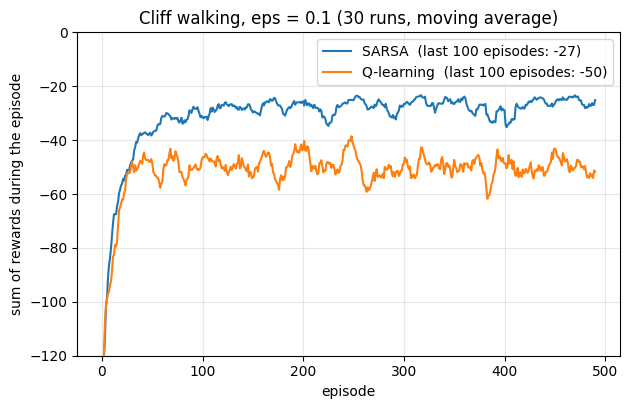


SARSA: greedy path, 17 steps
* * * * * * * * * * * *
* . . . . . . . . . . *
* . . . . . . . . . . *
S C C C C C C C C C C G

Q-learning: greedy path, 13 steps
. . . . . . . . . . . .
. . . . . . . . . . . .
* * * * * * * * * * * *
S C C C C C C C C C C G


In [3]:
results = {m: [cliff_control(m, seed=i) for i in range(30)] for m in ['SARSA', 'Q-learning']}

def smooth(x, w=10):
    return np.convolve(x, np.ones(w) / w, mode='valid')

for m, runs in results.items():
    R = np.mean([ret for _, ret in runs], axis=0)
    plt.plot(smooth(R), label=f'{m}  (last 100 episodes: {R[-100:].mean():.0f})')
plt.ylim(-120, 0); plt.xlabel('episode'); plt.ylabel('sum of rewards during the episode')
plt.title('Cliff walking, eps = 0.1 (30 runs, moving average)'); plt.legend(); plt.grid(alpha=.3); plt.show()


def greedy_path(Q):
    s, _ = env.reset(seed=0)
    path = [s]
    for _ in range(100):
        s, r, terminated, truncated, _ = env.step(int(Q[s].argmax()))
        path.append(s)
        if terminated:
            break
    return path

def print_path(Q):
    grid = np.full((4, 12), '.')
    grid[3, 1:11] = 'C'; grid[3, 0] = 'S'; grid[3, 11] = 'G'
    for s in greedy_path(Q)[1:-1]:
        grid[divmod(s, 12)] = '*'
    for row in grid:
        print(' '.join(row))

# greedy policy of the Q-table averaged over the 30 runs (a single run may never have visited
# some states, and its greedy policy can then walk into a wall forever)
Q_avg = {m: np.mean([Q for Q, _ in runs], axis=0) for m, runs in results.items()}
for m, Q in Q_avg.items():
    print(f'\n{m}: greedy path, {len(greedy_path(Q)) - 1} steps')
    print_path(Q)

**Question 6.** Explain both results. Q-learning's greedy path is shorter, so why is its reward during learning worse? Which algorithm would you trust to drive a real robot while it is still learning?

**Answer.** Q-learning learns $Q^*$, whose greedy policy walks right along the edge of the cliff (13 steps, the optimal path). But it **behaves** ε-greedily while learning, and on the edge a random step (probability $\varepsilon/4$ per step of going down) sends it into the cliff for −100; so its reward during learning is about −50 per episode. SARSA learns the value of the ε-greedy policy it actually follows, which includes those accidental falls; states next to the cliff get low values and its greedy policy keeps a safe distance (17 steps along the top), earning about −27 per episode during learning. So the "optimal" policy is optimal only if it is executed without exploration noise. For a robot that learns while acting (and where falling is real), SARSA's cautious, on-policy behavior is the safer choice; if learning happens in a simulator and the learned policy is then run greedily, Q-learning's answer is better. As $\varepsilon\to0$ both converge to the optimal path.

### Watch the learned policies

`play` runs one greedy episode and animates Gymnasium's own frames (use the ◀ ▶ buttons). Greedy means ε = 0, so neither agent falls.

In [4]:
def play(env, Q, title='', interval=300):
    s, _ = env.reset(seed=0)
    frames, done = [env.render()], False
    for _ in range(100):
        s, r, terminated, truncated, _ = env.step(int(Q[s].argmax()))
        frames.append(env.render())
        if terminated or truncated:
            break
    fig, ax = plt.subplots(figsize=(8, 3))
    im = ax.imshow(frames[0]); ax.axis('off'); ax.set_title(f'{title}: {len(frames) - 1} steps')
    anim = animation.FuncAnimation(fig, lambda i: [im.set_array(frames[i])], frames=len(frames), interval=interval)
    plt.close(fig)
    return HTML(anim.to_jshtml(default_mode='once'))

display(play(env, Q_avg['SARSA'], 'SARSA'))
display(play(env, Q_avg['Q-learning'], 'Q-learning'))